In [90]:
import os
import pandas as pd
import constants
tot = 0
with_co2 = 0

# for file in os.listdir("imputed_envirocar_data"):
#     df = pd.read_csv("imputed_envirocar_data"+'/'+file)
#     if 'CO2(kg/h)' in df.columns:
#         with_co2 += 1
#     tot += 1
dd_ = None
for a in constants.all_columns_present_id_list[:10]:
    print(a)
    df = pd.read_csv("imputed_envirocar_data"+'/'+a+'.csv')
    dd_ = df[constants.required_columns[2:-1]]
dd_

661245119828af15e2717fed
6612450a9828af15e2717c76
660b61e09828af15e232d0c3
660b61da9828af15e232ce12
65eeef0527de036499a72864
65eeef0a27de036499a72b1b
65ab9613769a4a5c859dbad6
65ab9617769a4a5c859dbead
65ab9626769a4a5c859dc49a
65ab962a769a4a5c859dc820


,GPS Bearing(deg),GPS HDOP(precision),GPS Altitude(m),Consumption(l/h),Speed(km/h),Rpm(u/min),Throttle Position(%),Intake Temperature(c),Engine Load(%)
0,46.373896,1.100000,104.215118,1.596518,13.781898,921.0,4.0,3.0,16.470589
1,45.995188,1.100000,104.172172,1.647913,3.000000,818.0,5.0,3.0,21.568628
2,45.563026,0.800000,104.194939,1.607622,0.000000,798.0,4.0,3.0,23.921568
3,45.563026,1.100000,104.236220,1.579418,0.000000,784.0,4.0,3.0,23.588470
4,45.563028,1.100000,104.283080,1.374026,0.000000,752.0,3.0,3.0,20.392157
...,...,...,...,...,...,...,...,...,...
172,57.703997,0.875848,105.820291,3.914743,22.000000,1674.0,8.5,9.0,43.137257
173,69.083872,0.900000,105.800114,2.921544,22.000000,1554.0,12.0,9.0,37.058824
174,73.667812,0.900000,105.781926,6.288790,25.000000,2078.0,12.0,9.0,43.921570
175,75.086590,0.900000,105.924984,4.505998,28.000000,1920.0,11.0,8.0,38.039215


In [91]:
print(tot, with_co2)

0 0


136901
134269


<Axes: xlabel='0', ylabel='1'>

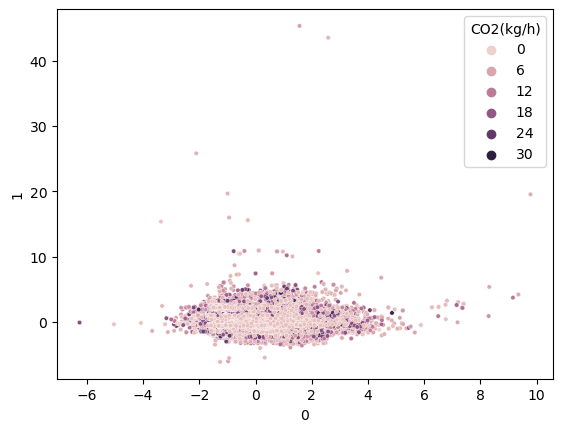

In [143]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# print(pca.singular_values_)
# print(pca.get_covariance())

# scaled

# df_pca = pd.DataFrame(df_pca, list(range(2)))

# df = pd.read_csv("imputed_envirocar_data"+'/'+a+'.csv')
# df_pca[constants.required_columns[1]] = 
fin = None
scaled = None
for a in constants.all_columns_present_id_list[:1]:
    # print(a)
    df = pd.read_csv("imputed_envirocar_data"+'/'+a+'.csv')
    dd_ = df[constants.required_columns[2:-1]]
    pca = PCA(n_components = 2)
    pca.fit(dd_)
    scaled = pd.DataFrame(StandardScaler().fit_transform(dd_))
    df_pca = pca.transform(scaled)
    df_pca = pd.DataFrame(StandardScaler().fit_transform(df_pca))
    df_pca[constants.required_columns[1]] = df[constants.required_columns[1]]
    fin = df_pca

for a in constants.all_columns_present_id_list[1:]:
    # print(a)
    df = pd.read_csv("imputed_envirocar_data"+'/'+a+'.csv')
    dd_ = df[constants.required_columns[2:-1]]
    pca = PCA(n_components = 2)
    pca.fit(dd_)
    scaled = pd.DataFrame(StandardScaler().fit_transform(dd_))
    df_pca = pca.transform(scaled)
    fin = pd.concat([pd.DataFrame(StandardScaler().fit_transform(df_pca)), fin], ignore_index=True)
    fin[constants.required_columns[1]] = pd.concat([fin[constants.required_columns[1]].dropna(), df[constants.required_columns[1]]], ignore_index=True)
    # fin = df_pca
# fin
print(len(fin))
fin = fin[np.abs(stats.zscore(fin['CO2(kg/h)']) <= 3)]
print(len(fin))
sns.scatterplot(data=fin, x=0, y=1, hue='CO2(kg/h)', s=10)

In [148]:
da = None
for a in constants.all_columns_present_id_list:
    print(a)
    df = pd.read_csv("imputed_envirocar_data"+'/'+a+'.csv')
    da = df['Calculated MAF(g/s)']
da

661245119828af15e2717fed
6612450a9828af15e2717c76
660b61e09828af15e232d0c3
660b61da9828af15e232ce12
65eeef0527de036499a72864
65eeef0a27de036499a72b1b
65ab9613769a4a5c859dbad6
65ab9617769a4a5c859dbead
65ab9626769a4a5c859dc49a
65ab962a769a4a5c859dc820
659fa485e4334e110cc91523
65868308e4334e110cc30bc0
6586830ce4334e110cc31030
65868321e4334e110cc31e25
65868325e4334e110cc32271
657d6e21e4334e110c29a519
657d6e27e4334e110c29a61d
65716543e4334e110c24925a
655efd4de4334e110cefdb1c
655efd53e4334e110cefddca
6520ed349186d0330638b754
6520ed2f9186d0330638b4ac
64fc075ade656f7b9eefe24f
64fc075ade656f7b9eefe364
64fc0aebde656f7b9ef01ce2
64b1008ac7e42807e7eabb2f
64b10090c7e42807e7eabeb2
649e5fc6c7e42807e751c2ff
649e5fcac7e42807e751c64f
64952e3cc7e42807e74b6939
64952e41c7e42807e74b71d5
648acd0ac7e42807e7038f32
6482e20eca0a730aef0f3c67
6481cd86ca0a730aefddb8f3
64725ad0ca0a730aef50ed59
646dc14dca0a730aef443b5f
646dc174ca0a730aef445de9
645f34ccca0a730aef36fad2
645f34cfca0a730aef36fdb6
644eb8cfca0a730aef197857


KeyError: 'Calculated MAF(g/s)'

In [150]:
import torch

ModuleNotFoundError: No module named 'torch'